<a href="https://colab.research.google.com/github/johnpoppa/semaforo-climatico-visitas/blob/main/Semaforo_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
#!/usr/bin/env python3
"""
Semáforo climático para agenda de visitas técnicas (Open-Meteo).

Consulta el pronóstico a 3 días por localidad, lo resume por día y franja
(mañana / tarde) y calcula un nivel de riesgo: VERDE / AMARILLO / ROJO.
Compara los resultados con la última ejecución para alertar desvíos.

Salida: riesgo_climatico.csv (y riesgo_climatico_previo.csv para control)
"""
import argparse
import sys
import time
import os
import pandas as pd
import requests

API_URL = "https://api.open-meteo.com/v1/forecast"
TIMEZONE = "America/Argentina/Buenos_Aires"
BATCH_SIZE = 50  # localidades por request

# Franjas horarias (hora inicio inclusive, hora fin inclusive)
FRANJAS = {"manana": (8, 13), "tarde": (14, 19)}

# Umbrales de riesgo
UMBRALES = {
    "prob_amarillo": 30,   # % probabilidad de lluvia
    "prob_rojo": 60,
    "mm_amarillo": 1.0,    # mm acumulados en la franja
    "mm_rojo": 5.0,
    "racha_amarillo": 40,  # km/h
    "racha_rojo": 60,
}

# Códigos WMO de tormenta eléctrica
CODIGOS_TORMENTA = {95, 96, 99}

LOCALIDADES_EJEMPLO = [
    ("Córdoba", "Córdoba", -31.4201, -64.1888),
    ("Córdoba", "Río Cuarto", -33.1307, -64.3499),
    ("Buenos Aires", "CABA", -34.6037, -58.3816),
    ("Buenos Aires", "La Plata", -34.9205, -57.9536),
    ("Santa Fe", "Rosario", -32.9442, -60.6505),
    ("Santa Fe", "Santa Fe", -31.6333, -60.7000),
    ("Mendoza", "Mendoza", -32.8895, -68.8458),
    ("Tucumán", "San Miguel de Tucumán", -26.8083, -65.2176),
    ("Salta", "Salta", -24.7821, -65.4232),
    ("Entre Ríos", "Paraná", -31.7333, -60.5333),
    ("Misiones", "Posadas", -27.3671, -55.8961),
    ("Neuquén", "Neuquén", -38.9516, -68.0591),
]

NIVEL_ORDEN = {"VERDE": 0, "AMARILLO": 1, "ROJO": 2}


def cargar_localidades(path):
    if path:
        df = pd.read_csv(path)
        faltan = {"provincia", "localidad", "lat", "lon"} - set(df.columns)
        if faltan:
            sys.exit(f"Faltan columnas en {path}: {faltan}")
        return df
    return pd.DataFrame(LOCALIDADES_EJEMPLO, columns=["provincia", "localidad", "lat", "lon"])


def consultar_batch(batch, dias):
    params = {
        "latitude": ",".join(str(x) for x in batch["lat"]),
        "longitude": ",".join(str(x) for x in batch["lon"]),
        "hourly": "precipitation_probability,precipitation,wind_gusts_10m,weather_code",
        "forecast_days": dias,
        "timezone": TIMEZONE,
        "wind_speed_unit": "kmh",
    }
    for intento in range(3):
        try:
            r = requests.get(API_URL, params=params, timeout=30)
            r.raise_for_status()
            data = r.json()
            return data if isinstance(data, list) else [data]
        except requests.RequestException as e:
            print(f"  Error de red (intento {intento + 1}/3): {e}", file=sys.stderr)
            time.sleep(2 * (intento + 1))
    sys.exit("No se pudo consultar Open-Meteo.")


def nivel_riesgo(prob, mm, racha, tormenta):
    u = UMBRALES
    if tormenta or prob > u["prob_rojo"] or mm > u["mm_rojo"] or racha >= u["racha_rojo"]:
        return "ROJO"
    if prob >= u["prob_amarillo"] or mm >= u["mm_amarillo"] or racha >= u["racha_amarillo"]:
        return "AMARILLO"
    return "VERDE"


def resumir(loc, resp):
    h = pd.DataFrame(resp["hourly"])
    h["time"] = pd.to_datetime(h["time"])
    h["fecha"] = h["time"].dt.date
    h["hora"] = h["time"].dt.hour

    filas = []
    for fecha, dia in h.groupby("fecha"):
        for franja, (ini, fin) in FRANJAS.items():
            t = dia[(dia["hora"] >= ini) & (dia["hora"] <= fin)]
            if t.empty:
                continue
            prob = float(t["precipitation_probability"].max())
            mm = float(t["precipitation"].sum())
            racha = float(t["wind_gusts_10m"].max())
            tormenta = bool(t["weather_code"].isin(CODIGOS_TORMENTA).any())
            filas.append({
                "provincia": loc["provincia"],
                "localidad": loc["localidad"],
                "lat": loc["lat"],
                "lon": loc["lon"],
                "fecha": str(fecha),
                "franja": franja,
                "prob_lluvia_max_pct": round(prob, 0),
                "lluvia_mm": round(mm, 1),
                "racha_max_kmh": round(racha, 0),
                "tormenta_electrica": tormenta,
                "nivel": nivel_riesgo(prob, mm, racha, tormenta),
            })
    return filas


def detectar_cambios_significativos(archivo_anterior, archivo_nuevo):
    """Compara el reporte anterior con el nuevo para detectar riesgos incrementados."""
    if not os.path.exists(archivo_anterior):
        print("ℹ️ No hay un reporte previo para comparar. Se omitirá la detección de cambios en esta ejecución.")
        return []

    previo = pd.read_csv(archivo_anterior)
    nuevo = pd.read_csv(archivo_nuevo)

    # Unir ambos reportes por fecha, localidad y franja
    comparativa = pd.merge(
        previo, nuevo,
        on=['fecha', 'localidad', 'franja'],
        suffixes=('_previo', '_nuevo')
    )

    alertas = []
    nivel_map = {'VERDE': 0, 'AMARILLO': 1, 'ROJO': 2}

    for _, fila in comparativa.iterrows():
        nivel_pre = nivel_map.get(fila['nivel_previo'], 0)
        nivel_nue = nivel_map.get(fila['nivel_nuevo'], 0)

        # 1. El nivel de riesgo empeoró
        if nivel_nue > nivel_pre:
            alertas.append(
                f"🚨 RIESGO EMPEORÓ en {fila['localidad']} ({fila['fecha']} - {fila['franja']}): "
                f"Subió de {fila['nivel_previo']} a {fila['nivel_nuevo']}."
            )
        # 2. La probabilidad de lluvia aumentó en un 30% o más
        elif (fila['prob_lluvia_max_pct_nuevo'] - fila['prob_lluvia_max_pct_previo']) >= 30:
            alertas.append(
                f"⚠️ ALERTA DE LLUVIA en {fila['localidad']} ({fila['fecha']} - {fila['franja']}): "
                f"Probabilidad de lluvia subió de {fila['prob_lluvia_max_pct_previo']}% a {fila['prob_lluvia_max_pct_nuevo']}%."
            )

    return alertas


def main(args_list=None):
    ap = argparse.ArgumentParser(description="Semáforo climático para visitas técnicas")
    ap.add_argument("--localidades", help="CSV: provincia,localidad,lat,lon")
    ap.add_argument("--dias", type=int, default=3, help="Días de pronóstico (default 3)")
    ap.add_argument("--salida", default="riesgo_climatico.csv")

    if args_list is not None:
        args = ap.parse_args(args_list)
    else:
        args, _ = ap.parse_known_args()

    # Rotar el archivo de salida actual si existe para usarlo como histórico previo
    archivo_previo = args.salida.replace(".csv", "_previo.csv")
    if os.path.exists(args.salida):
        if os.path.exists(archivo_previo):
            os.remove(archivo_previo)
        os.rename(args.salida, archivo_previo)
        print(f"🔄 Archivo previo rotado a: {archivo_previo}")

    locs = cargar_localidades(args.localidades).reset_index(drop=True)
    filas = []

    for i in range(0, len(locs), BATCH_SIZE):
        batch = locs.iloc[i:i + BATCH_SIZE]
        print(f"Consultando localidades {i + 1}-{i + len(batch)} de {len(locs)}...")
        respuestas = consultar_batch(batch, args.dias)
        for (_, loc), resp in zip(batch.iterrows(), respuestas):
            filas.extend(resumir(loc, resp))
        time.sleep(1)

    df = pd.DataFrame(filas)
    df["orden"] = df["nivel"].map(NIVEL_ORDEN)
    df = df.sort_values(["fecha", "orden", "provincia", "localidad", "franja"],
                        ascending=[True, False, True, True, True]).drop(columns="orden")
    df.to_csv(args.salida, index=False, encoding="utf-8-sig")
    print(f"💾 Guardado: {args.salida} ({len(df)} filas)\n")

    # Ejecutar la detección de cambios automáticos comparándolo con el histórico rotado
    alertas_cambios = detectar_cambios_significativos(archivo_previo, args.salida)
    if alertas_cambios:
        print("\n=== ⚠️ DETECCION DE CAMBIOS SIGNIFICATIVOS ===")
        for alerta in alertas_cambios:
            print(alerta)
        print("===============================================\n")
    else:
        print("\n✅ No se detectaron desmejoras climáticas significativas frente al reporte anterior.")


if __name__ == "__main__":
    if 'ipykernel' in sys.modules:
        main(args_list=[])
    else:
        main()

🔄 Archivo previo rotado a: riesgo_climatico_previo.csv
Consultando localidades 1-12 de 12...
💾 Guardado: riesgo_climatico.csv (72 filas)


✅ No se detectaron desmejoras climáticas significativas frente al reporte anterior.


### 💾 Integración y Persistencia en Google Drive

El siguiente bloque de código monta tu Google Drive de manera interactiva y copia automáticamente los reportes generados a una carpeta dedicada para asegurar la persistencia histórica de tus datos.

In [16]:
import os
import pandas as pd
from google.colab import drive
from google.colab import files

# 1. Intentar montar Google Drive con manejo de excepciones
try:
    print("Conectando con Google Drive... (Por favor, si aparece una ventana emergente, acepta los permisos)")
    drive.mount('/content/drive', force_remount=True)
    drive_conectado = True
except Exception as e:
    print(f"\n⚠ No se pudo montar Google Drive de forma automática ({e}).")
    print("No te preocupes. Puedes descargar el archivo directamente a tu computadora usando la opción alternativa al final de esta celda.\n")
    drive_conectado = False

# 2. Si Drive está conectado, guardar el histórico
if drive_conectado:
    DRIVE_FOLDER = '/content/drive/MyDrive/Semaforo_Climatico'
    os.makedirs(DRIVE_FOLDER, exist_ok=True)

    path_actual = 'riesgo_climatico.csv'
    path_drive_actual = os.path.join(DRIVE_FOLDER, 'riesgo_climatico_ultimo.csv')
    path_drive_historico = os.path.join(DRIVE_FOLDER, 'historico_acumulado.csv')

    if os.path.exists(path_actual):
        df_nuevo = pd.read_csv(path_actual)
        df_nuevo.to_csv(path_drive_actual, index=False, encoding='utf-8-sig')
        print(f"✓ Copia del reporte actual guardada en Drive: {path_drive_actual}")

        # Mantener registro acumulativo
        df_nuevo['fecha_ejecucion'] = pd.Timestamp.now(tz='America/Argentina/Buenos_Aires').strftime('%Y-%m-%d %H:%M:%S')

        if os.path.exists(path_drive_historico):
            df_hist = pd.read_csv(path_drive_historico)
            df_acumulado = pd.concat([df_hist, df_nuevo], ignore_index=True)
            df_acumulado.drop_duplicates(subset=['fecha', 'localidad', 'franja', 'fecha_ejecucion'], inplace=True)
        else:
            df_acumulado = df_nuevo

        df_acumulado.to_csv(path_drive_historico, index=False, encoding='utf-8-sig')
        print(f"✓ Histórico acumulativo actualizado en Drive: {path_drive_historico} ({len(df_acumulado)} registros en total)")
    else:
        print("⚠ No se encontró el archivo 'riesgo_climatico.csv' local. Por favor, ejecuta primero la celda del script climático.")
else:
    # Alternativa: Descarga directa al navegador local
    print("--- DESCARGA ALTERNATIVA ---")
    path_actual = 'riesgo_climatico.csv'
    if os.path.exists(path_actual):
        print("Descargando el archivo local 'riesgo_climatico.csv' directamente a tu dispositivo...")
        files.download(path_actual)
    else:
        print("⚠ No se encontró el archivo 'riesgo_climatico.csv' local para descargar.")

Conectando con Google Drive... (Por favor, si aparece una ventana emergente, acepta los permisos)

⚠ No se pudo montar Google Drive de forma automática (Error: credential propagation was unsuccessful).
No te preocupes. Puedes descargar el archivo directamente a tu computadora usando la opción alternativa al final de esta celda.

--- DESCARGA ALTERNATIVA ---
Descargando el archivo local 'riesgo_climatico.csv' directamente a tu dispositivo...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 📦 Exportación de Archivos de Scripts (.py)

Ejecuta las siguientes celdas en tu notebook para escribir directamente en el almacenamiento de Colab los archivos independientes `.py` listos para ser subidos a tu repositorio de GitHub.

In [17]:
%%writefile semaforo_climatico.py
#!/usr/bin/env python3
"""
Semáforo climático para agenda de visitas técnicas (Open-Meteo).

Consulta el pronóstico a 3 días por localidad, lo resume por día y franja
(mañana / tarde), calcula un nivel de riesgo (VERDE / AMARILLO / ROJO)
y compara los resultados con la ejecución previa para detectar cambios.
"""
import argparse
import sys
import time
import os
import pandas as pd
import requests

API_URL = "https://api.open-meteo.com/v1/forecast"
TIMEZONE = "America/Argentina/Buenos_Aires"
BATCH_SIZE = 50
FRANJAS = {"manana": (8, 13), "tarde": (14, 19)}
UMBRALES = {
    "prob_amarillo": 30,
    "prob_rojo": 60,
    "mm_amarillo": 1.0,
    "mm_rojo": 5.0,
    "racha_amarillo": 40,
    "racha_rojo": 60,
}
CODIGOS_TORMENTA = {95, 96, 99}

LOCALIDADES_EJEMPLO = [
    ("Córdoba", "Córdoba", -31.4201, -64.1888),
    ("Córdoba", "Río Cuarto", -33.1307, -64.3499),
    ("Buenos Aires", "CABA", -34.6037, -58.3816),
    ("Buenos Aires", "La Plata", -34.9205, -57.9536),
    ("Santa Fe", "Rosario", -32.9442, -60.6505),
    ("Santa Fe", "Santa Fe", -31.6333, -60.7000),
    ("Mendoza", "Mendoza", -32.8895, -68.8458),
    ("Tucumán", "San Miguel de Tucumán", -26.8083, -65.2176),
    ("Salta", "Salta", -24.7821, -65.4232),
    ("Entre Ríos", "Paraná", -31.7333, -60.5333),
    ("Misiones", "Posadas", -27.3671, -55.8961),
    ("Neuquén", "Neuquén", -38.9516, -68.0591),
]

NIVEL_ORDEN = {"VERDE": 0, "AMARILLO": 1, "ROJO": 2}

def cargar_localidades(path):
    if path and os.path.exists(path):
        df = pd.read_csv(path)
        return df
    return pd.DataFrame(LOCALIDADES_EJEMPLO, columns=["provincia", "localidad", "lat", "lon"])

def consultar_batch(batch, dias):
    params = {
        "latitude": ",".join(str(x) for x in batch["lat"]),
        "longitude": ",".join(str(x) for x in batch["lon"]),
        "hourly": "precipitation_probability,precipitation,wind_gusts_10m,weather_code",
        "forecast_days": dias,
        "timezone": TIMEZONE,
        "wind_speed_unit": "kmh",
    }
    for intento in range(3):
        try:
            r = requests.get(API_URL, params=params, timeout=30)
            r.raise_for_status()
            data = r.json()
            return data if isinstance(data, list) else [data]
        except Exception as e:
            print(f"  Error de red: {e}", file=sys.stderr)
            time.sleep(2)
    sys.exit("No se pudo consultar Open-Meteo.")

def nivel_riesgo(prob, mm, racha, tormenta):
    u = UMBRALES
    if tormenta or prob > u["prob_rojo"] or mm > u["mm_rojo"] or racha >= u["racha_rojo"]:
        return "ROJO"
    if prob >= u["prob_amarillo"] or mm >= u["mm_amarillo"] or racha >= u["racha_amarillo"]:
        return "AMARILLO"
    return "VERDE"

def resumir(loc, resp):
    h = pd.DataFrame(resp["hourly"])
    h["time"] = pd.to_datetime(h["time"])
    h["fecha"] = h["time"].dt.date
    h["hora"] = h["time"].dt.hour

    filas = []
    for fecha, dia in h.groupby("fecha"):
        for franja, (ini, fin) in FRANJAS.items():
            t = dia[(dia["hora"] >= ini) & (dia["hora"] <= fin)]
            if t.empty: continue
            prob = float(t["precipitation_probability"].max())
            mm = float(t["precipitation"].sum())
            racha = float(t["wind_gusts_10m"].max())
            tormenta = bool(t["weather_code"].isin(CODIGOS_TORMENTA).any())
            filas.append({
                "provincia": loc["provincia"],
                "localidad": loc["localidad"],
                "lat": loc["lat"],
                "lon": loc["lon"],
                "fecha": str(fecha),
                "franja": franja,
                "prob_lluvia_max_pct": round(prob, 0),
                "lluvia_mm": round(mm, 1),
                "racha_max_kmh": round(racha, 0),
                "tormenta_electrica": tormenta,
                "nivel": nivel_riesgo(prob, mm, racha, tormenta),
            })
    return filas

def detectar_cambios_significativos(archivo_anterior, archivo_nuevo):
    if not os.path.exists(archivo_anterior):
        return []
    previo = pd.read_csv(archivo_anterior)
    nuevo = pd.read_csv(archivo_nuevo)
    comparativa = pd.merge(previo, nuevo, on=['fecha', 'localidad', 'franja'], suffixes=('_previo', '_nuevo'))

    alertas = []
    nivel_map = {'VERDE': 0, 'AMARILLO': 1, 'ROJO': 2}
    for _, fila in comparativa.iterrows():
        nivel_pre = nivel_map.get(fila['nivel_previo'], 0)
        nivel_nue = nivel_map.get(fila['nivel_nuevo'], 0)
        if nivel_nue > nivel_pre:
            alertas.append(f"🚨 RIESGO EMPEORÓ: {fila['localidad']} ({fila['fecha']} - {fila['franja']}): de {fila['nivel_previo']} a {fila['nivel_nuevo']}.")
        elif (fila['prob_lluvia_max_pct_nuevo'] - fila['prob_lluvia_max_pct_previo']) >= 30:
            alertas.append(f"⚠️ LLUVIA EN ALZA: {fila['localidad']} ({fila['fecha']} - {fila['franja']}): probabilidad subió de {fila['prob_lluvia_max_pct_previo']}% a {fila['prob_lluvia_max_pct_nuevo']}%.")
    return alertas

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--localidades", default=None)
    ap.add_argument("--dias", type=int, default=3)
    ap.add_argument("--salida", default="riesgo_climatico.csv")
    args = ap.parse_args()

    archivo_previo = args.salida.replace(".csv", "_previo.csv")
    if os.path.exists(args.salida):
        if os.path.exists(archivo_previo): os.remove(archivo_previo)
        os.rename(args.salida, archivo_previo)

    locs = cargar_localidades(args.localidades)
    filas = []
    for i in range(0, len(locs), BATCH_SIZE):
        batch = locs.iloc[i:i + BATCH_SIZE]
        respuestas = consultar_batch(batch, args.dias)
        for (_, loc), resp in zip(batch.iterrows(), respuestas):
            filas.extend(resumir(loc, resp))

    df = pd.DataFrame(filas)
    df["orden"] = df["nivel"].map(NIVEL_ORDEN)
    df = df.sort_values(["fecha", "orden", "provincia", "localidad", "franja"], ascending=[True, False, True, True, True]).drop(columns="orden")
    df.to_csv(args.salida, index=False, encoding="utf-8-sig")
    print(f"💾 Archivo guardado correctamente en: {args.salida}")

    alertas_cambios = detectar_cambios_significativos(archivo_previo, args.salida)
    if alertas_cambios:
        print("\n=== ⚠️ ALERTAS DE CAMBIOS ===")
        for a in alertas_cambios:
            print(a)
    else:
        print("\n✅ Sin alertas frente a la última medición.")

if __name__ == "__main__":
    main()

Writing semaforo_climatico.py


In [18]:
%%writefile graficador.py
#!/usr/bin/env python3
"""
Generador de Reporte Visual en formato Imagen PNG.
"""
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def generar_grafica(archivo_csv="riesgo_climatico.csv", output_img="distribucion_alertas.png"):
    if not os.path.exists(archivo_csv):
        print(f"⚠ Error: No se encontró el archivo {archivo_csv}")
        sys.exit(1)

    df_riesgos = pd.read_csv(archivo_csv)
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(12, 7))

    order_riesgos = ['VERDE', 'AMARILLO', 'ROJO']
    colores = {'VERDE': '#2ca02c', 'AMARILLO': '#ff7f0e', 'ROJO': '#d62728'}

    ax = sns.countplot(
        data=df_riesgos,
        x='localidad',
        hue='nivel',
        hue_order=order_riesgos,
        palette=colores
    )

    plt.title('Distribución de Alertas Climáticas por Localidad (Próximos 3 días)', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Localidad', fontsize=11, labelpad=10)
    plt.ylabel('Cantidad de Franjas Horarias', fontsize=11, labelpad=10)
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.legend(title='Nivel de Riesgo', fontsize=10, title_fontsize=11)

    for container in ax.containers:
        ax.bar_label(container, fmt='%d', label_type='edge', padding=2, fontsize=8)

    plt.tight_layout()
    plt.savefig(output_img, dpi=150)
    print(f"📊 Gráfica exportada con éxito como: {output_img}")

if __name__ == "__main__":
    generar_grafica()

Writing graficador.py


In [19]:
%%writefile analisis_historico.py
#!/usr/bin/env python3
"""
Procesador analítico de métricas: rankings provinciales y filtros de riesgos.
"""
import sys
import os
import pandas as pd

def correr_analisis(archivo_csv="riesgo_climatico.csv"):
    if not os.path.exists(archivo_csv):
        print(f"⚠ No se encontró el archivo {archivo_csv}")
        sys.exit(1)

    df = pd.read_csv(archivo_csv)
    print("\n--- RANKING DE SEGURIDAD POR PROVINCIA ---")
    resumen = df.groupby('provincia').agg(
        total_franjas=('nivel', 'count'),
        franjas_verdes=('nivel', lambda x: (x == 'VERDE').sum()),
        franjas_rojas=('nivel', lambda x: (x == 'ROJO').sum())
    ).reset_index()
    resumen['porcentaje_seguro'] = (resumen['franjas_verdes'] / resumen['total_franjas']) * 100
    resumen = resumen.sort_values(by=['porcentaje_seguro', 'franjas_rojas'], ascending=[False, True])
    print(resumen.to_string(index=False))

    print("\n--- RESUMEN ESPECÍFICO DE VISITAS CRÍTICAS EN PARANÁ ---")
    df_parana = df[df['localidad'].str.lower() == 'paraná']
    if not df_parana.empty:
        columnas = ['fecha', 'franja', 'nivel', 'prob_lluvia_max_pct', 'lluvia_mm', 'racha_max_kmh']
        print(df_parana[columnas].to_string(index=False))
    else:
        print("No se encontraron registros de la localidad 'Paraná'.")

if __name__ == "__main__":
    correr_analisis()

Writing analisis_historico.py


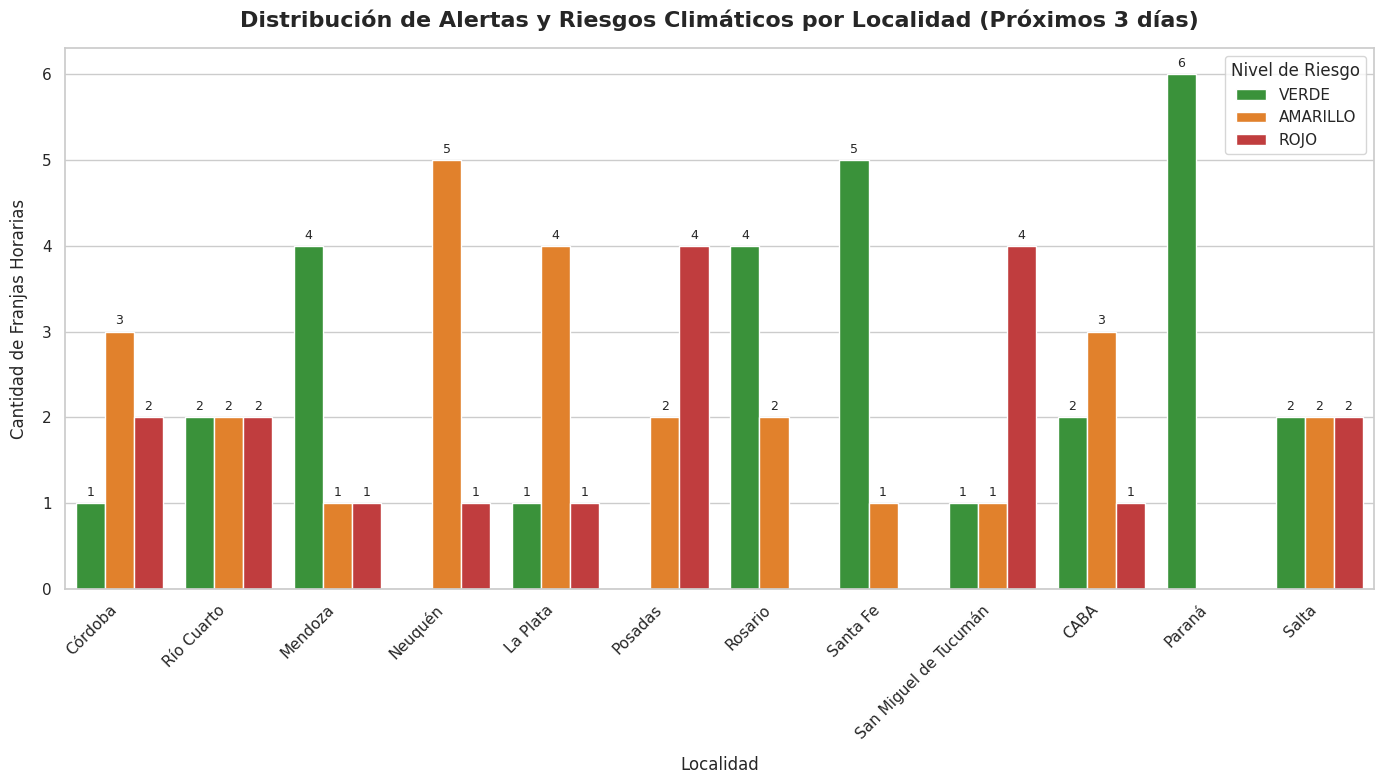

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los datos generados
df_riesgos = pd.read_csv('riesgo_climatico.csv')

# Configurar el estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 8))

# Crear un gráfico de barras agrupado por localidad y nivel de riesgo
# Contamos la cantidad de franjas horarias en cada nivel de riesgo para cada localidad
order_riesgos = ['VERDE', 'AMARILLO', 'ROJO']
colores = {'VERDE': '#2ca02c', 'AMARILLO': '#ff7f0e', 'ROJO': '#d62728'}

ax = sns.countplot(
    data=df_riesgos,
    x='localidad',
    hue='nivel',
    hue_order=order_riesgos,
    palette=colores
)

# Personalizar el gráfico
plt.title('Distribución de Alertas y Riesgos Climáticos por Localidad (Próximos 3 días)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Localidad', fontsize=12, labelpad=10)
plt.ylabel('Cantidad de Franjas Horarias', fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.legend(title='Nivel de Riesgo', fontsize=11, title_fontsize=12)

# Añadir etiquetas de valor sobre las barras
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

In [9]:
# Filtrar y mostrar los registros de Paraná en el DataFrame para analizar sus niveles de riesgo
df_parana = df_riesgos[df_riesgos['localidad'].str.lower() == 'paraná']
display(df_parana[['fecha', 'franja', 'nivel', 'prob_lluvia_max_pct', 'lluvia_mm', 'racha_max_kmh']])

,fecha,franja,nivel,prob_lluvia_max_pct,lluvia_mm,racha_max_kmh
16,2026-11-16,manana,VERDE,6.0,0.0,24.0
17,2026-11-16,tarde,VERDE,20.0,0.2,22.0
41,2026-11-17,manana,VERDE,12.0,0.1,36.0
42,2026-11-17,tarde,VERDE,5.0,0.0,32.0
65,2026-11-18,manana,VERDE,22.0,0.0,20.0
66,2026-11-18,tarde,VERDE,18.0,0.0,29.0


In [10]:
# Analizar el porcentaje de franjas seguras (VERDE) por provincia en los próximos 3 días
# Evaluamos la cantidad total de franjas seguras sobre el total de franjas pronosticadas por provincia
resumen_seguridad = df_riesgos.groupby('provincia').agg(
    total_franjas=('nivel', 'count'),
    franjas_verdes=('nivel', lambda x: (x == 'VERDE').sum()),
    franjas_rojas=('nivel', lambda x: (x == 'ROJO').sum())
).reset_index()

resumen_seguridad['porcentaje_seguro'] = (resumen_seguridad['franjas_verdes'] / resumen_seguridad['total_franjas']) * 100
resumen_seguridad = resumen_seguridad.sort_values(by=['porcentaje_seguro', 'franjas_rojas'], ascending=[False, True])

print("Ranking de seguridad por Provincia:")
display(resumen_seguridad)

Ranking de seguridad por Provincia:


,provincia,total_franjas,franjas_verdes,franjas_rojas,porcentaje_seguro
2,Entre Ríos,6,6,0,100.000000
7,Santa Fe,12,9,0,75.000000
3,Mendoza,6,4,1,66.666667
6,Salta,6,2,2,33.333333
0,Buenos Aires,12,3,2,25.000000
1,Córdoba,12,3,4,25.000000
8,Tucumán,6,1,4,16.666667
5,Neuquén,6,0,1,0.000000
4,Misiones,6,0,4,0.000000


In [11]:
import os
import pandas as pd

def detectar_cambios_significativos(archivo_anterior='riesgo_climatico_previo.csv', archivo_nuevo='riesgo_climatico.csv'):
    """
    Compara el reporte anterior con el nuevo y devuelve una lista de alertas
    si el riesgo empeoró o si cambiaron mucho las variables cuantitativas.
    """
    if not os.path.exists(archivo_anterior):
        print("No hay un reporte previo para comparar. Se creará uno nuevo.")
        return []

    previo = pd.read_csv(archivo_anterior)
    nuevo = pd.read_csv(archivo_nuevo)

    # Unir ambos reportes por fecha, localidad y franja
    comparativa = pd.merge(
        previo, nuevo,
        on=['fecha', 'localidad', 'franja'],
        suffixes=('_previo', '_nuevo')
    )

    alertas = []
    nivel_map = {'VERDE': 0, 'AMARILLO': 1, 'ROJO': 2}

    for _, fila in comparativa.iterrows():
        nivel_pre = nivel_map.get(fila['nivel_previo'], 0)
        nivel_nue = nivel_map.get(fila['nivel_nuevo'], 0)

        # Condición 1: El nivel de riesgo empeoró (Ej: de VERDE a AMARILLO/ROJO)
        if nivel_nue > nivel_pre:
            alertas.append(
                f"🚨 CAMBIO DE RIESGO en {fila['localidad']} ({fila['fecha']} - {fila['franja']}): "
                f"Subió de {fila['nivel_previo']} a {fila['nivel_nuevo']}."
            )
        # Condición 2: La probabilidad de lluvia aumentó en más de un 30%
        elif (fila['prob_lluvia_max_pct_nuevo'] - fila['prob_lluvia_max_pct_previo']) >= 30:
            alertas.append(
                f"⚠️ AUMENTO DE LLUVIA en {fila['localidad']} ({fila['fecha']} - {fila['franja']}): "
                f"Probabilidad subió de {fila['prob_lluvia_max_pct_previo']}% a {fila['prob_lluvia_max_pct_nuevo']}%."
            )

    return alertas

# Ejemplo de ejecución conceptual
# alertas_detectadas = detectar_cambios_significativos()
# if alertas_detectadas:
#     enviar_notificacion_slack_o_email(alertas_detectadas)

### 2. ¿Cómo programar la ejecución automática dos veces al día?

Como Google Colab está diseñado para ejecución interactiva y apaga la máquina virtual tras un periodo de inactividad, no es el entorno ideal para automatizaciones 24/7. Para lograr que corra de **lunes a sábado a las 9:00 y a las 15:00**, se recomiendan las siguientes alternativas:

#### Opción A: GitHub Actions (La más recomendada, 100% Gratuita)
Si guardas tu script de Python en un repositorio de GitHub, puedes configurar un servicio gratuito llamado **GitHub Actions**. Este ejecutará tu script automáticamente usando una tarea programada (*cron job*).

Creas un archivo `.github/workflows/semaforo.yml` en tu repositorio con la siguiente regla de tiempo:
```yaml
on:
  schedule:
    # Corre de lunes (1) a sábado (6) a las 12:00 UTC (9:00 AM de Argentina)
    # y a las 18:00 UTC (15:00 PM de Argentina)
    - cron: '0 12,18 * * 1-6'
```
En esa misma tarea, el script puede autoejecutarse, comparar los resultados con el reporte anterior, enviar un correo (usando librerías como `smtplib` o APIs como SendGrid) y actualizar un dashboard en Power BI.

#### Opción B: Tarea programada en Servidor Propio / Nube (Linux/Windows)
Si cuentas con un servidor virtual (AWS, Google Cloud, Azure o una máquina de la oficina que siempre esté encendida):
* **En Linux**: Utilizas el programador `cron` agregando estas dos líneas usando `crontab -e`:
  ```bash
  0 9 * * 1-6 /usr/bin/python3 /ruta/al/semaforo_climatico.py >> /ruta/al/log.txt 2>&1
  0 15 * * 1-6 /usr/bin/python3 /ruta/al/semaforo_climatico.py >> /ruta/al/log.txt 2>&1
  ```
* **En Windows**: Creas una tarea en el **Programador de Tareas de Windows** que ejecute el intérprete de Python apuntando al script en esos horarios.

### 🛠️ Configuración Detallada de Automatización

A continuación, se presentan las plantillas de configuración listas para usar según el método de automatización que prefieras.

### 🚀 Guía de Configuración para GitHub Actions (Actualizado: Guardado automático y Envío de Email)

Para que los reportes se guarden en tu repositorio y además los recibas automáticamente por correo electrónico, realiza la siguiente configuración:

#### 🔑 Configuración previa en GitHub:
1. **Permisos de Escritura:** Ve a **Settings** -> **Actions** -> **General** -> Selecciona **Read and write permissions** -> Clic en **Save**.
2. **Secretos para el Correo:** Ve a **Settings** -> **Secrets and variables** -> **Actions** -> Haz clic en **New repository secret** y crea estos tres secretos:
   * `SMTP_USER`: Tu dirección de correo emisora (ej: `tu_cuenta@gmail.com`).
   * `SMTP_PASSWORD`: Tu contraseña de aplicación (en tu cuenta de Google, ve a Seguridad -> Verificación en 2 pasos -> Contraseñas de aplicación y genera una nueva contraseña de 16 caracteres).
   * `RECEIVER_EMAIL`: El correo destino que recibirá las alertas.

#### 📄 Código de `.github/workflows/semaforo.yml` actualizado:

```yaml
name: Ejecución Semáforo Climático Automático

on:
  schedule:
    # Corre de lunes (1) a sábado (6) a las 12:00 UTC (9:00 AM de Argentina)
    # y a las 18:00 UTC (3:00 PM de Argentina)
    - cron: '0 12,18 * * 1-6'
  workflow_dispatch: # Permite ejecución manual

jobs:
  run-pipeline:
    runs-on: ubuntu-latest

    steps:
    - name: Descargar Código del Repositorio
      uses: actions/checkout@v4

    - name: Inicializar Entorno de Python
      uses: actions/setup-python@v5
      with:
        python-version: '3.10'

    - name: Instalar Dependencias del Sistema
      run: |
        python -m pip install --upgrade pip
        pip install requests pandas matplotlib seaborn

    - name: Ejecutar Extracción del Semáforo Climático
      run: |
        python semaforo_climatico.py

    - name: Ejecutar Análisis y Generar Alertas por Consola
      run: |
        python analisis_historico.py

    - name: Generar Reporte Gráfico PNG
      run: |
        python graficador.py

    # Guarda los archivos generados físicamente en el repositorio
    - name: Guardar cambios en el repositorio de GitHub
      run: |
        git config --global user.name "github-actions[bot]"
        git config --global user.email "github-actions[bot]@users.noreply.github.com"
        git add riesgo_climatico.csv riesgo_climatico_previo.csv distribucion_alertas.png
        git diff --quiet && git diff --staged --quiet || (git commit -m "🔄 Auto-actualización de reportes climáticos [Skip GitHub Actions]" && git push)

    # NUEVO PASO: Envía un correo con los archivos y el gráfico adjuntos
    - name: Enviar Reporte por Correo Electrónico
      uses: dawidd6/action-send-mail@v4
      with:
        server_address: smtp.gmail.com
        server_port: 465
        secure: true
        username: ${{ secrets.SMTP_USER }}
        password: ${{ secrets.SMTP_PASSWORD }}
        subject: "🌦️ Alerta y Reporte del Semáforo Climático - Actualización Automática"
        to: ${{ secrets.RECEIVER_EMAIL }}
        from: "Semáforo Climático Automático <${{ secrets.SMTP_USER }}>"
        body: |
          Hola,
          
          Se ha completado una nueva ejecución del Semáforo Climático.
          
          Adjunto a este correo encontrarás:
          1. 'riesgo_climatico.csv' - El análisis detallado de riesgos de los próximos 3 días.
          2. 'distribucion_alertas.png' - El gráfico visual de distribución de alertas por localidad.
          
          ---
          Este es un correo automático generado por GitHub Actions.
        attachments: riesgo_climatico.csv,distribucion_alertas.png
```

In [1]:
import os

# Definir el nombre incorrecto y el correcto
nombre_incorrecto = 'semaforo_climatico (1).py'
nombre_correcto = 'semaforo_climatico.py'

# Verificar si existe el archivo con el nombre incorrecto y renombrarlo
if os.path.exists(nombre_incorrecto):
    os.rename(nombre_incorrecto, nombre_correcto)
    print(f"¡Listo! El archivo ha sido renombrado con éxito a: '{nombre_correcto}'")
else:
    if os.path.exists(nombre_correcto):
        print(f"El archivo ya está guardado con el nombre correcto: '{nombre_correcto}'")
    else:
        print("No se encontró el archivo temporal. Asegúrate de haber subido o generado el archivo en este entorno.")

No se encontró el archivo temporal. Asegúrate de haber subido o generado el archivo en este entorno.


#### Opción B: Configuración para Servidor Linux (`cron`)

Si usas un servidor propio o una instancia en la nube (VPS) con Linux, puedes programar la tarea usando el servicio local de `cron`:

1. Entra a la terminal de tu servidor.
2. Abre el editor de tareas programadas con el comando:
   ```bash
   crontab -e
   ```
3. Añade las siguientes líneas al final del archivo para ejecutar el script a las 9:00 y a las 15:00 de lunes a sábado:

```bash
# --------------------------------------------------------------------------
# Minuto Hora DíaMes Mes DíaSemana Comando
# --------------------------------------------------------------------------
# Corre a las 09:00 de Lunes a Sábado
0 9 * * 1-6 /usr/bin/python3 /ruta/absoluta/a/semaforo_climatico.py >> /ruta/absoluta/a/ejecucion_semaforo.log 2>&1

# Corre a las 15:00 de Lunes a Sábado
0 15 * * 1-6 /usr/bin/python3 /ruta/absoluta/a/semaforo_climatico.py >> /ruta/absoluta/a/ejecucion_semaforo.log 2>&1
```

*Consejo práctico:* Asegúrate de reemplazar `/ruta/absoluta/a/` por el directorio real donde se encuentre tu script en el servidor (por ejemplo, `/home/usuario/scripts/`).